# Coffee Sales — Midterm Notebook

EDA, feature analysis, and model selection for predicting `coffee_name` from transaction context (machine 1).


In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import randint
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

from data_utils import (
    TARGET_COLUMN,
    engineer_features,
    get_training_frame,
    load_all_raw,
)

sns.set_theme(style="whitegrid")
%matplotlib inline


In [2]:
m1, m2 = load_all_raw()
print("Machine 1:", m1.shape)
print("Machine 2:", m2.shape)
m1.head()


Machine 1: (3636, 7)
Machine 2: (262, 7)


,date,datetime,cash_type,card,money,coffee_name,machine_id
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte,machine_1
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate,machine_1
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate,machine_1
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano,machine_1
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte,machine_1


Missing values (machine 1):
date            0
datetime        0
cash_type       0
card           89
money           0
coffee_name     0
machine_id      0
hour            0
day_of_week     0
month           0
is_weekend      0
has_card        0
dtype: int64

Target distribution (machine 1):
                     count
coffee_name               
Americano with Milk    824
Latte                  782
Americano              578
Cappuccino             501
Cortado                292
Hot Chocolate          282
Cocoa                  243
Espresso               134


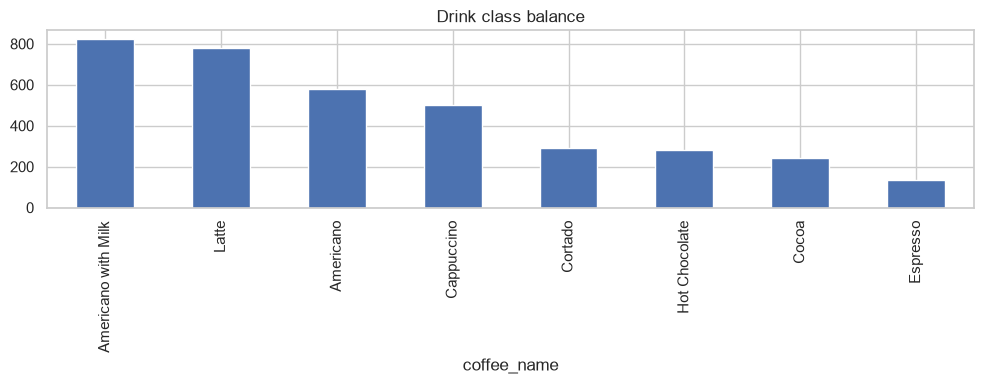

In [3]:
eda1 = engineer_features(m1)
eda2 = engineer_features(m2)
print("Missing values (machine 1):")
print(eda1.isna().sum())
print("\nTarget distribution (machine 1):")
target_counts = eda1[TARGET_COLUMN].value_counts().sort_values(ascending=False)
print(target_counts.to_frame("count"))
target_counts.plot(kind="bar", title="Drink class balance", figsize=(10, 4))
plt.tight_layout()
plt.show()


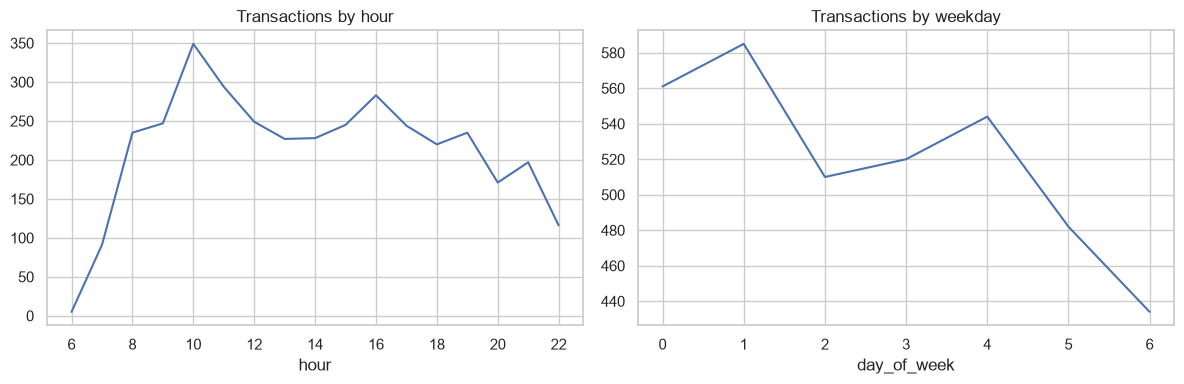

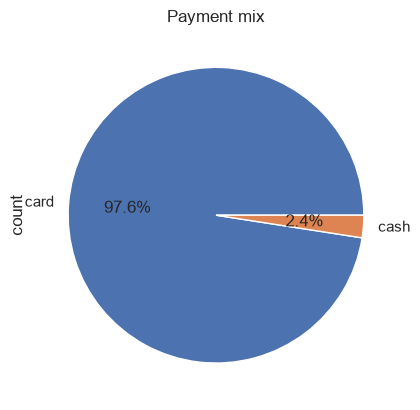

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
eda1.groupby("hour").size().plot(ax=axes[0], title="Transactions by hour")
eda1.groupby("day_of_week").size().plot(ax=axes[1], title="Transactions by weekday")
plt.tight_layout()
plt.show()
eda1["cash_type"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Payment mix")
plt.show()


In [5]:
print("Unique drinks machine 2:", eda2[TARGET_COLUMN].nunique())
print("Overlap with machine 1:", set(eda1[TARGET_COLUMN]) & set(eda2[TARGET_COLUMN]))


Unique drinks machine 2: 30
Overlap with machine 1: {'Americano', 'Cappuccino', 'Espresso', 'Latte'}


In [6]:
x, y = get_training_frame()
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)
x_train.shape, x_test.shape


((2908, 6), (728, 6))

## Feature importance (numeric correlation vs encoded target)


In [7]:
target_codes = y.astype("category").cat.codes
numeric = x.select_dtypes(include=[np.number])
corrs = numeric.corrwith(pd.Series(target_codes, index=x.index)).sort_values(
    key=abs, ascending=False
)
corrs


month          0.122862
hour           0.114430
is_weekend    -0.002914
day_of_week    0.002241
dtype: float64

In [8]:
pre = ColumnTransformer([
    ("num", StandardScaler(), ["hour", "day_of_week", "month", "is_weekend"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["cash_type", "has_card"]),
])

def evaluate(name, pipe):
    pipe.fit(x_train, y_train)
    pred = pipe.predict(x_test)
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
    }

lr_pipe = Pipeline([
    ("pre", pre),
    ("clf", LogisticRegression(max_iter=2000, random_state=42)),
])
lr_metrics = evaluate("logistic_regression", lr_pipe)
lr_metrics


{'model': 'logistic_regression',
 'accuracy': 0.27884615384615385,
 'f1_macro': 0.12961904881809524}

In [9]:
rf_base = Pipeline([
    ("pre", pre),
    ("clf", RandomForestClassifier(random_state=42, class_weight="balanced")),
])
rf_metrics = evaluate("random_forest_baseline", rf_base)
rf_metrics


{'model': 'random_forest_baseline',
 'accuracy': 0.23763736263736263,
 'f1_macro': 0.22848303556703453}

In [10]:
rf_search = RandomizedSearchCV(
    Pipeline([
        ("pre", pre),
        ("clf", RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1)),
    ]),
    param_distributions={
        "clf__n_estimators": randint(50, 200),
        "clf__max_depth": [None, 10, 20, 30],
        "clf__min_samples_leaf": randint(1, 5),
    },
    n_iter=15,
    cv=3,
    scoring="f1_macro",
    random_state=42,
    n_jobs=1,
)
rf_search.fit(x_train, y_train)
rf_tuned_pred = rf_search.predict(x_test)
rf_tuned = {
    "model": "random_forest_tuned",
    "accuracy": accuracy_score(y_test, rf_tuned_pred),
    "f1_macro": f1_score(y_test, rf_tuned_pred, average="macro"),
    "best_params": rf_search.best_params_,
}
rf_tuned


{'model': 'random_forest_tuned',
 'accuracy': 0.23763736263736263,
 'f1_macro': 0.2277550070479127,
 'best_params': {'clf__max_depth': 10,
  'clf__min_samples_leaf': 1,
  'clf__n_estimators': 138}}

In [11]:
xgb_result = None
if HAS_XGB:
    xgb_search = RandomizedSearchCV(
        Pipeline([
            ("pre", pre),
            ("clf", XGBClassifier(
                objective="multi:softprob",
                eval_metric="mlogloss",
                random_state=42,
                n_jobs=-1,
            )),
        ]),
        param_distributions={
            "clf__n_estimators": randint(50, 200),
            "clf__max_depth": randint(3, 10),
            "clf__learning_rate": [0.05, 0.1, 0.2],
        },
        n_iter=12,
        cv=3,
        scoring="f1_macro",
        random_state=42,
        n_jobs=1,
    )
    from sklearn.preprocessing import LabelEncoder
    label_encoder = LabelEncoder()
    y_train_enc = label_encoder.fit_transform(y_train)
    y_test_enc = label_encoder.transform(y_test)
    xgb_search.fit(x_train, y_train_enc)
    xgb_pred = label_encoder.inverse_transform(xgb_search.predict(x_test))
    xgb_result = {
        "model": "xgboost_tuned",
        "accuracy": accuracy_score(y_test, xgb_pred),
        "f1_macro": f1_score(y_test, xgb_pred, average="macro"),
        "best_params": xgb_search.best_params_,
    }
xgb_result


{'model': 'xgboost_tuned',
 'accuracy': 0.2802197802197802,
 'f1_macro': 0.22446022837922702,
 'best_params': {'clf__learning_rate': 0.2,
  'clf__max_depth': 6,
  'clf__n_estimators': 142}}

In [12]:
summary = pd.DataFrame([lr_metrics, rf_metrics, {
    "model": rf_tuned["model"],
    "accuracy": rf_tuned["accuracy"],
    "f1_macro": rf_tuned["f1_macro"],
}])
if xgb_result:
    summary = pd.concat([summary, pd.DataFrame([xgb_result])], ignore_index=True)
summary.sort_values("f1_macro", ascending=False)


,model,accuracy,f1_macro,best_params
1,random_forest_baseline,0.237637,0.228483,NaN
2,random_forest_tuned,0.237637,0.227755,NaN
3,xgboost_tuned,0.280220,0.224460,"{'clf__learning_rate': 0.2, 'clf__max_depth': ..."
0,logistic_regression,0.278846,0.129619,NaN


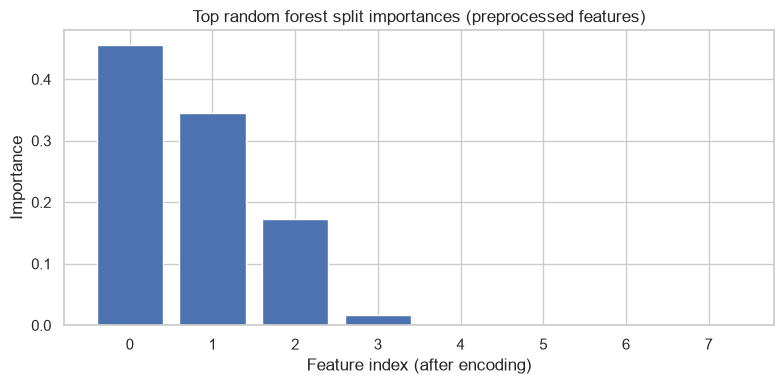

                     precision    recall  f1-score   support

          Americano       0.30      0.30      0.30       116
Americano with Milk       0.31      0.18      0.22       165
         Cappuccino       0.28      0.26      0.27       100
              Cocoa       0.22      0.35      0.27        49
            Cortado       0.19      0.34      0.24        58
           Espresso       0.05      0.15      0.08        27
      Hot Chocolate       0.18      0.25      0.21        56
              Latte       0.34      0.18      0.23       157

           accuracy                           0.24       728
          macro avg       0.23      0.25      0.23       728
       weighted avg       0.27      0.24      0.24       728



In [13]:
best = rf_search.best_estimator_
importances = best.named_steps["clf"].feature_importances_
plt.figure(figsize=(8, 4))
plt.bar(range(len(importances)), sorted(importances, reverse=True)[:15])
plt.title("Top random forest split importances (preprocessed features)")
plt.xlabel("Feature index (after encoding)")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()
print(classification_report(y_test, rf_tuned_pred))


## Final model

**Selected model:** tuned `RandomForestClassifier` (best macro-F1 on hold-out among compared models).

Export: run `python train.py` to refit on all machine 1 rows and save `models/pipeline.joblib`.
